#Install Dependencies

_(Remember to choose GPU in Runtime if not already selected. Runtime --> Change Runtime Type --> Hardware accelerator --> GPU)_

In [1]:
# clone YOLOR repository
!git clone https://github.com/roboflow-ai/yolor
%cd yolor

!git reset --hard eb3ef0b7472413d6740f5cde39beb1a2f5b8b5d1

Cloning into 'yolor'...
remote: Enumerating objects: 390, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 390 (delta 0), reused 0 (delta 0), pack-reused 387 (from 1)
Receiving objects: 100% (390/390), 2.97 MiB | 6.16 MiB/s, done.
Resolving deltas: 100% (173/173), done.
/content/yolor
HEAD is now at eb3ef0b indentation


In [2]:
# Install necessary dependencies
!pip install -qr requirements.txt

ERROR: Could not find a version that satisfies the requirement torch==1.7.0 (from versions: 1.11.0, 1.12.0, 1.12.1, 1.13.0, 1.13.1, 2.0.0, 2.0.1, 2.1.0, 2.1.1, 2.1.2, 2.2.0, 2.2.1, 2.2.2, 2.3.0, 2.3.1, 2.4.0)
ERROR: No matching distribution found for torch==1.7.0


In [3]:
# Install Mish CUDA
!git clone https://github.com/JunnYu/mish-cuda
%cd mish-cuda
!git reset --hard 6f38976064cbcc4782f4212d7c0c5f6dd5e315a8
!python setup.py build install
%cd ..

Cloning into 'mish-cuda'...
remote: Enumerating objects: 195, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 195 (delta 20), reused 20 (delta 20), pack-reused 169 (from 1)
Receiving objects: 100% (195/195), 203.57 KiB | 18.51 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/yolor/mish-cuda
HEAD is now at 6f38976 Update README.md
/usr/local/lib/python3.10/dist-packages/setuptools/_distutils/extension.py:134: UserWarning: Unknown Extension options: 'headers'
  warnings.warn(msg)
running build
running build_py
creating build
creating build/lib.linux-x86_64-cpython-310
creating build/lib.linux-x86_64-cpython-310/mish_cuda
copying src/mish_cuda/__init__.py -> build/lib.linux-x86_64-cpython-310/mish_cuda
running egg_info
creating src/mish_cuda.egg-info
writing src/mish_cuda.egg-info/PKG-INFO
writing dependency_links to src/mish_cuda.egg-info/dependency_links.txt
writing requirements to src/mish_cuda.egg-info/require

In [4]:
# Install PyTorch Wavelets
!git clone https://github.com/fbcotter/pytorch_wavelets
%cd pytorch_wavelets
!pip install .
%cd ..

Cloning into 'pytorch_wavelets'...
remote: Enumerating objects: 978, done.
remote: Counting objects: 100% (142/142), done.
remote: Compressing objects: 100% (96/96), done.
remote: Total 978 (delta 79), reused 91 (delta 46), pack-reused 836 (from 1)
Receiving objects: 100% (978/978), 6.80 MiB | 21.62 MiB/s, done.
Resolving deltas: 100% (663/663), done.
/content/yolor/pytorch_wavelets
Processing /content/yolor/pytorch_wavelets
  Preparing metadata (setup.py) ... done
  Created wheel for pytorch_wavelets: filename=pytorch_wavelets-1.3.0-py3-none-any.whl size=54850 sha256=d5067db53fb25466eefce1338d7f7384fb5fe21cb6ea55013612da5c366aa679
  Stored in directory: /tmp/pip-ephem-wheel-cache-tokz7p6a/wheels/67/2b/75/b238b39512b74de50324a5f8afb0180ba106a66bd01588bf0f
Successfully built pytorch_wavelets
/content/yolor


# Download Correctly Formatted Custom Dataset

We'll download our dataset from Roboflow. Use the "**YOLOv5 PyTorch**" export format. Note that the Ultralytics implementation calls for a YAML file defining where your training and test data is. The Roboflow export also writes this format for us.

To get your data into Roboflow, follow the [Getting Started Guide](https://blog.roboflow.ai/getting-started-with-roboflow/).

![YOLOv5 PyTorch export](https://i.imgur.com/5vr9G2u.png)


In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="daiwhoq3nbY046cOP9ri")
project = rf.workspace("ccu-yujy2").project("wli")
version = project.version(1)
dataset = version.download("yolov5")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.1 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to WLI-1 in yolov5pytorch:: 100%|██████████| 8262/8262 [00:01<00:00, 7597.67it/s]


In [6]:
# this is the YAML file Roboflow wrote for us that we're loading into this notebook with our data
%cat {dataset.location}/data.yaml

names:
- '0'
- '1'
- '10'
- '2'
- '3'
- '4'
- '5'
- '6'
- '7'
- '8'
- '9'
nc: 11
roboflow:
  license: CC BY 4.0
  project: wli
  url: https://universe.roboflow.com/ccu-yujy2/wli/dataset/1
  version: 1
  workspace: ccu-yujy2
test: ../test/images
train: WLI-1/train/images
val: WLI-1/valid/images


# Prepare Pre-Trained Weights for YOLOR

In [7]:
%cd /content/yolor
!wget https://huggingface.co/kadirnar/yolor-p6/resolve/main/yolor_p6.pt

/content/yolor
--2024-08-23 12:35:18--  https://huggingface.co/kadirnar/yolor-p6/resolve/main/yolor_p6.pt
Resolving huggingface.co (huggingface.co)... 13.33.28.94, 13.33.28.112, 13.33.28.87, ...
Connecting to huggingface.co (huggingface.co)|13.33.28.94|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://cdn-lfs.huggingface.co/repos/55/16/5516cc1fefa71567cfbe6866f89fd901ae2ea77af3f4a305af4d18478faa7826/d10691979a97a876578d10edfa0f904a14ca8e50f495bad0fdc2bd04eafd4f56?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27yolor_p6.pt%3B+filename%3D%22yolor_p6.pt%22%3B&Expires=1724675718&Policy=eyJTdGF0ZW1lbnQiOlt7IkNvbmRpdGlvbiI6eyJEYXRlTGVzc1RoYW4iOnsiQVdTOkVwb2NoVGltZSI6MTcyNDY3NTcxOH19LCJSZXNvdXJjZSI6Imh0dHBzOi8vY2RuLWxmcy5odWdnaW5nZmFjZS5jby9yZXBvcy81NS8xNi81NTE2Y2MxZmVmYTcxNTY3Y2ZiZTY4NjZmODlmZDkwMWFlMmVhNzdhZjNmNGEzMDVhZjRkMTg0NzhmYWE3ODI2L2QxMDY5MTk3OWE5N2E4NzY1NzhkMTBlZGZhMGY5MDRhMTRjYThlNTBmNDk1YmFkMGZkYzJiZDA0ZWFmZDRmNTY%7EcmVzcG9uc2UtY2

# Write YOLOR Configuration

In [8]:
import yaml
with open(dataset.location + "/data.yaml") as f:
    dataMap = yaml.safe_load(f)

num_classes = len(dataMap['names'])
num_filters = (num_classes + 5) * 3
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))

In [12]:
%%writetemplate /content/yolor/cfg/yolor_p6.cfg

[net]
batch=64
subdivisions=8
width=1280
height=1280
channels=3
momentum=0.949
decay=0.0005
angle=0
saturation = 1.5
exposure = 1.5
hue=.1

learning_rate=0.00261
burn_in=1000
max_batches = 500500
policy=steps
steps=400000,450000
scales=.1,.1

mosaic=1


# ============ Backbone ============ #

# Stem

# P1

# Downsample

# 0
[reorg]

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu


# P2

# Downsample

[convolutional]
batch_normalize=1
filters=128
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

# Transition first
#
#[convolutional]
#batch_normalize=1
#filters=64
#size=1
#stride=1
#pad=1
#activation=silu

# Merge [-1, -(3k+3)]

[route]
layers = -1,-12

# Transition last

# 16 (previous+6+3k)
[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu


# P3

# Downsample

[convolutional]
batch_normalize=1
filters=256
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

# Transition first
#
#[convolutional]
#batch_normalize=1
#filters=128
#size=1
#stride=1
#pad=1
#activation=silu

# Merge [-1, -(3k+3)]

[route]
layers = -1,-24

# Transition last

# 43 (previous+6+3k)
[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu


# P4

# Downsample

[convolutional]
batch_normalize=1
filters=384
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

# Transition first
#
#[convolutional]
#batch_normalize=1
#filters=192
#size=1
#stride=1
#pad=1
#activation=silu

# Merge [-1, -(3k+3)]

[route]
layers = -1,-24

# Transition last

# 70 (previous+6+3k)
[convolutional]
batch_normalize=1
filters=384
size=1
stride=1
pad=1
activation=silu


# P5

# Downsample

[convolutional]
batch_normalize=1
filters=512
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

# Transition first
#
#[convolutional]
#batch_normalize=1
#filters=256
#size=1
#stride=1
#pad=1
#activation=silu

# Merge [-1, -(3k+3)]

[route]
layers = -1,-12

# Transition last

# 85 (previous+6+3k)
[convolutional]
batch_normalize=1
filters=512
size=1
stride=1
pad=1
activation=silu


# P6

# Downsample

[convolutional]
batch_normalize=1
filters=640
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

# Transition first
#
#[convolutional]
#batch_normalize=1
#filters=320
#size=1
#stride=1
#pad=1
#activation=silu

# Merge [-1, -(3k+3)]

[route]
layers = -1,-12

# Transition last

# 100 (previous+6+3k)
[convolutional]
batch_normalize=1
filters=640
size=1
stride=1
pad=1
activation=silu

# ============ End of Backbone ============ #

# ============ Neck ============ #

# CSPSPP

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=320
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

### SPP ###
[maxpool]
stride=1
size=5

[route]
layers=-2

[maxpool]
stride=1
size=9

[route]
layers=-4

[maxpool]
stride=1
size=13

[route]
layers=-1,-3,-5,-6
### End SPP ###

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=320
activation=silu

[route]
layers = -1, -13

# 115 (previous+6+5+2k)
[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

# End of CSPSPP


# FPN-5

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[upsample]
stride=2

[route]
layers = 85

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[route]
layers = -1, -3

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

# Merge [-1, -(2k+2)]

[route]
layers = -1, -8

# Transition last

# 131 (previous+6+4+2k)
[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu


# FPN-4

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[upsample]
stride=2

[route]
layers = 70

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[route]
layers = -1, -3

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

# Merge [-1, -(2k+2)]

[route]
layers = -1, -8

# Transition last

# 147 (previous+6+4+2k)
[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu


# FPN-3

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[upsample]
stride=2

[route]
layers = 43

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[route]
layers = -1, -3

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=128
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=128
activation=silu

[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=128
activation=silu

# Merge [-1, -(2k+2)]

[route]
layers = -1, -8

# Transition last

# 163 (previous+6+4+2k)
[convolutional]
batch_normalize=1
filters=128
size=1
stride=1
pad=1
activation=silu


# PAN-4

[convolutional]
batch_normalize=1
size=3
stride=2
pad=1
filters=192
activation=silu

[route]
layers = -1, 147

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=192
activation=silu

[route]
layers = -1,-8

# Transition last

# 176 (previous+3+4+2k)
[convolutional]
batch_normalize=1
filters=192
size=1
stride=1
pad=1
activation=silu


# PAN-5

[convolutional]
batch_normalize=1
size=3
stride=2
pad=1
filters=256
activation=silu

[route]
layers = -1, 131

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[route]
layers = -1,-8

# Transition last

# 189 (previous+3+4+2k)
[convolutional]
batch_normalize=1
filters=256
size=1
stride=1
pad=1
activation=silu


# PAN-6

[convolutional]
batch_normalize=1
size=3
stride=2
pad=1
filters=320
activation=silu

[route]
layers = -1, 115

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

# Plain Block

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=320
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=320
activation=silu

[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=320
activation=silu

[route]
layers = -1,-8

# Transition last

# 202 (previous+3+4+2k)
[convolutional]
batch_normalize=1
filters=320
size=1
stride=1
pad=1
activation=silu

# ============ End of Neck ============ #

# 203
[implicit_add]
filters=256

# 204
[implicit_add]
filters=384

# 205
[implicit_add]
filters=512

# 206
[implicit_add]
filters=640

# 207
[implicit_mul]
filters={num_filters}

# 208
[implicit_mul]
filters={num_filters}

# 209
[implicit_mul]
filters={num_filters}

# 210
[implicit_mul]
filters={num_filters}

# ============ Head ============ #

# YOLO-3

[route]
layers = 163

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=256
activation=silu

[shift_channels]
from=203

[convolutional]
size=1
stride=1
pad=1
filters={num_filters}
activation=linear

[control_channels]
from=207

[yolo]
mask = 0,1,2
anchors = 19,27,  44,40,  38,94,  96,68,  86,152,  180,137,  140,301,  303,264,  238,542,  436,615,  739,380,  925,792
classes={num_classes}
num=12
jitter=.3
ignore_thresh = .7
truth_thresh = 1
random=1
scale_x_y = 1.05
iou_thresh=0.213
cls_normalizer=1.0
iou_normalizer=0.07
iou_loss=ciou
nms_kind=greedynms
beta_nms=0.6


# YOLO-4

[route]
layers = 176

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=384
activation=silu

[shift_channels]
from=204

[convolutional]
size=1
stride=1
pad=1
filters={num_filters}
activation=linear

[control_channels]
from=208

[yolo]
mask = 3,4,5
anchors = 19,27,  44,40,  38,94,  96,68,  86,152,  180,137,  140,301,  303,264,  238,542,  436,615,  739,380,  925,792
classes={num_classes}
num=12
jitter=.3
ignore_thresh = .7
truth_thresh = 1
random=1
scale_x_y = 1.05
iou_thresh=0.213
cls_normalizer=1.0
iou_normalizer=0.07
iou_loss=ciou
nms_kind=greedynms
beta_nms=0.6


# YOLO-5

[route]
layers = 189

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=512
activation=silu

[shift_channels]
from=205

[convolutional]
size=1
stride=1
pad=1
filters={num_filters}
activation=linear

[control_channels]
from=209

[yolo]
mask = 6,7,8
anchors = 19,27,  44,40,  38,94,  96,68,  86,152,  180,137,  140,301,  303,264,  238,542,  436,615,  739,380,  925,792
classes={num_classes}
num=12
jitter=.3
ignore_thresh = .7
truth_thresh = 1
random=1
scale_x_y = 1.05
iou_thresh=0.213
cls_normalizer=1.0
iou_normalizer=0.07
iou_loss=ciou
nms_kind=greedynms
beta_nms=0.6


# YOLO-6

[route]
layers = 202

[convolutional]
batch_normalize=1
size=3
stride=1
pad=1
filters=640
activation=silu

[shift_channels]
from=206

[convolutional]
size=1
stride=1
pad=1
filters={num_filters}
activation=linear

[control_channels]
from=210

[yolo]
mask = 9,10,11
anchors = 19,27,  44,40,  38,94,  96,68,  86,152,  180,137,  140,301,  303,264,  238,542,  436,615,  739,380,  925,792
classes={num_classes}
num=12
jitter=.3
ignore_thresh = .7
truth_thresh = 1
random=1
scale_x_y = 1.05
iou_thresh=0.5
cls_normalizer=1.0
iou_normalizer=0.07
iou_loss=ciou
nms_kind=greedynms
beta_nms=0.6

# ============ End of Head ============ #

In [13]:
%cat /content/yolor/cfg/yolor_p6.cfg


[net]
batch=64
subdivisions=8
width=1280
height=1280
channels=3
momentum=0.949
decay=0.0005
angle=0
saturation = 1.5
exposure = 1.5
hue=.1

learning_rate=0.00261
burn_in=1000
max_batches = 500500
policy=steps
steps=400000,450000
scales=.1,.1

mosaic=1


# ============ Backbone ============ #

# Stem

# P1

# Downsample

# 0
[reorg]

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu


# P2

# Downsample

[convolutional]
batch_normalize=1
filters=128
size=3
stride=2
pad=1
activation=silu

# Split

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[route]
layers = -2

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

# Residual Block

[convolutional]
batch_normalize=1
filters=64
size=1
stride=1
pad=1
activation=silu

[convolutional]
batch_normalize=1
filters=64
size=3
stride=1
pad=1
activation=silu

[shortcut]
from=-3
activation=linear

[convolutional]
batch_normalize=1
filters=64
size=1


# Train Custom YOLOR Detector

### Next, we'll fire off training!


Here, we are able to pass a number of arguments:
- **img:** define input image size
- **batch:** determine batch size
- **epochs:** define the number of training epochs. (Note: often, 3000+ are common here!)
- **data:** set the path to our yaml file
- **cfg:** specify our model configuration
- **weights:** specify a custom path to weights. (Note: We can specify the pretrained weights we downloaded up above with the shell script)
- **name:** result names
-**hyp:** Define the hyperparamters for training

In [11]:
import os

# Define the paths to the files
datasets_file = '/content/yolor/utils/datasets.py'
general_file = '/content/yolor/utils/general.py'

# Function to replace np.int with int in a file
def replace_np_int(file_path):
    # Read the file content
    with open(file_path, 'r') as file:
        content = file.read()

    # Replace np.int with int
    content = content.replace('(np.int)', '(int)')

    # Write the updated content back to the file
    with open(file_path, 'w') as file:
        file.write(content)

# Replace np.int in the specified files
replace_np_int(datasets_file)
replace_np_int(general_file)

print("Replaced 'np.int' with 'int' in datasets.py and general.py")

Replaced 'np.int' with 'int' in datasets.py and general.py


## Replace the loss.py and plot.py

In [14]:
%cd /content/yolor
!python train.py --batch-size 16 --img 640 640 --data {dataset.location}/data.yaml --cfg cfg/yolor_p6.cfg --weights '/content/yolor/yolor_p6.pt' --device 0 --name yolor_p6 --hyp '/content/yolor/data/hyp.scratch.1280.yaml' --epochs 600

/content/yolor
2024-08-23 12:43:25.502576: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-08-23 12:43:25.520198: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-23 12:43:25.541141: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-23 12:43:25.547611: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-23 12:43:25.562852: I tensorflow/core/platform/c

# Evaluate Custom YOLOR Detector Performance

Training losses and performance metrics are saved to Tensorboard and also to a logfile defined above with the **--name** flag when we train. In our case, we named this `yolor_p6`. (If given no name, it defaults to `results.txt`.) The results file is plotted as a png after training completes.

In [15]:
# Start tensorboard
# Launch after you have started training
# logs save in the folder "runs"
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

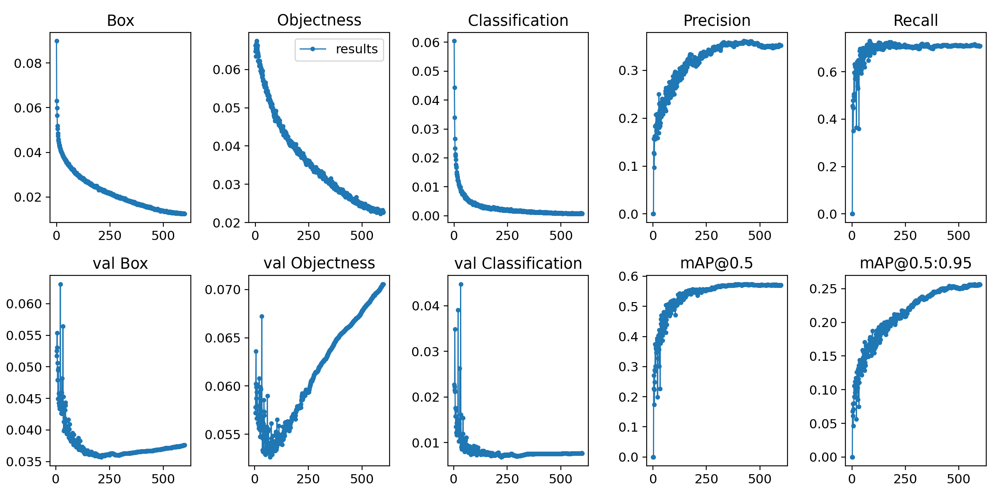

In [16]:
from IPython.display import Image
# we can also output some older school graphs if the tensor board isn't working for whatever reason...
from utils.plots import plot_results  # plot results.txt as results.png
Image(filename='/content/yolor/runs/train/yolor_p6/results.png', width=1000)  # view results.png

GROUND TRUTH TRAINING DATA:


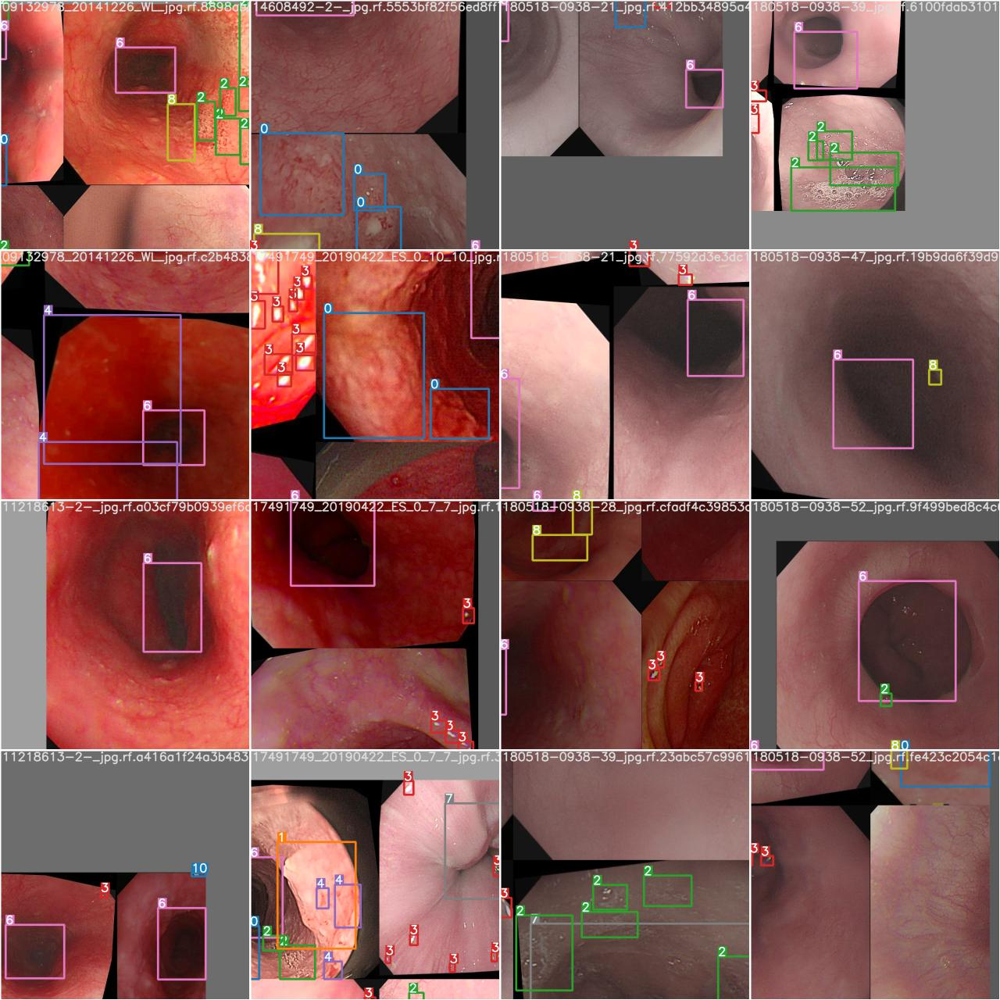

In [17]:
# first, display our ground truth data
print("GROUND TRUTH TRAINING DATA:")
Image(filename='/content/yolor/runs/train/yolor_p6/train_batch0.jpg', width=900)

AUGMENTED DATA:


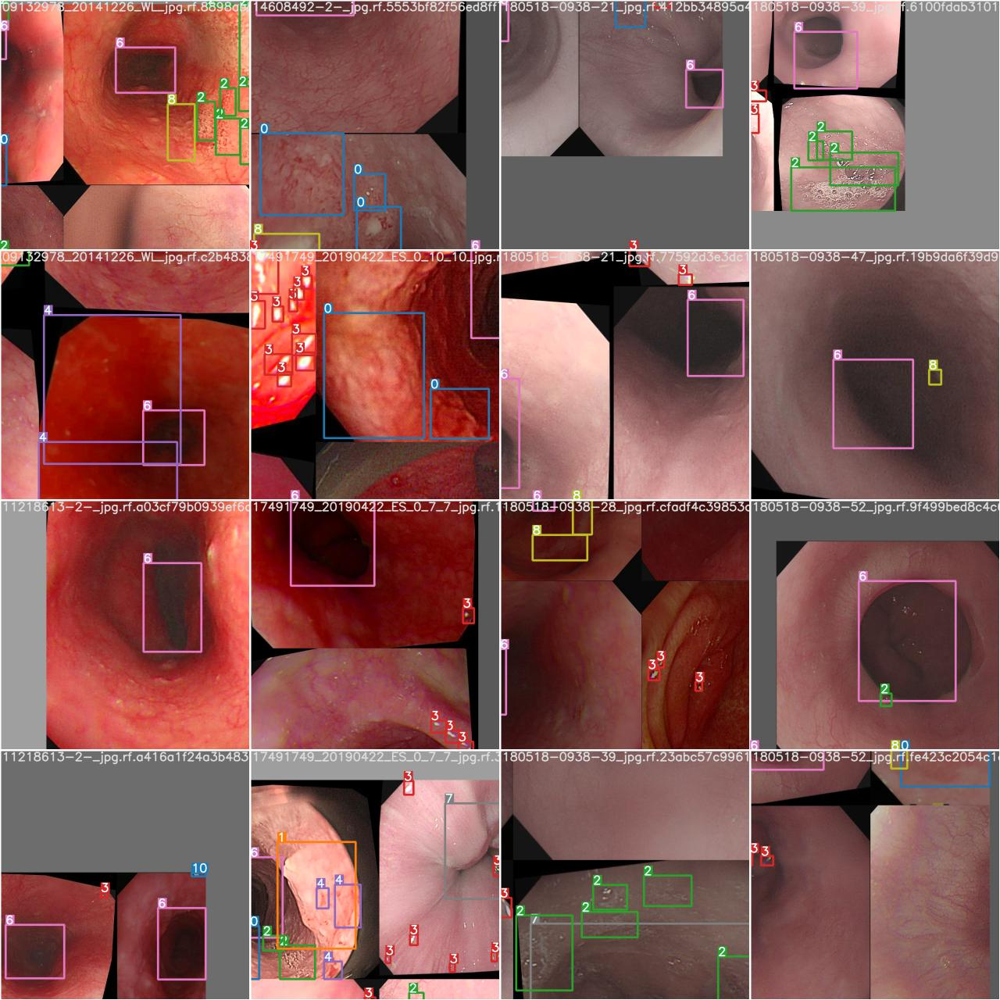

In [18]:
print("AUGMENTED DATA:")
Image(filename='/content/yolor/runs/train/yolor_p6/train_batch0.jpg', width=900)

#Run Inference  With Trained Weights
Run inference with a pretrained checkpoint on contents of `test/images` folder downloaded from Roboflow.

In [19]:
# trained weights are saved by default in our weights folder
%ls runs/

train/


In [20]:
%ls runs/train/yolor_p6/weights

best_213.pt  best_370.pt      best_r.pt     last_435.pt  last_477.pt  last_519.pt  last_561.pt
best_232.pt  best_372.pt      epoch_000.pt  last_436.pt  last_478.pt  last_520.pt  last_562.pt
best_233.pt  best_374.pt      epoch_024.pt  last_437.pt  last_479.pt  last_521.pt  last_563.pt
best_261.pt  best_375.pt      epoch_049.pt  last_438.pt  last_480.pt  last_522.pt  last_564.pt
best_263.pt  best_379.pt      epoch_074.pt  last_439.pt  last_481.pt  last_523.pt  last_565.pt
best_264.pt  best_380.pt      epoch_099.pt  last_440.pt  last_482.pt  last_524.pt  last_566.pt
best_268.pt  best_381.pt      epoch_124.pt  last_441.pt  last_483.pt  last_525.pt  last_567.pt
best_269.pt  best_387.pt      epoch_149.pt  last_442.pt  last_484.pt  last_526.pt  last_568.pt
best_272.pt  best_394.pt      epoch_174.pt  last_443.pt  last_485.pt  last_527.pt  last_569.pt
best_273.pt  best_395.pt      epoch_199.pt  last_444.pt  last_486.pt  last_528.pt  last_570.pt
best_274.pt  best_396.pt      epoch_224.pt  last_4

In [26]:
# Create names file for model
import yaml
import ast
with open("/content/yolor/WLI-1/data.yaml", 'r') as stream:
    names = str(yaml.safe_load(stream)['names'])

namesFile = open("../data.names", "w+")
names = ast.literal_eval(names)
for name in names:
  namesFile.write(name +'\n')
namesFile.close()

In [28]:
  !python detect.py --weights "runs/train/yolor_p6/weights/best_overall.pt" --conf 0.7 --source /content/yolor/WLI-1/test/images --names ../data.names --cfg cfg/yolor_p6.cfg

Namespace(weights=['runs/train/yolor_p6/weights/best_overall.pt'], source='/content/yolor/WLI-1/test/images', output='inference/output', img_size=1280, conf_thres=0.7, iou_thres=0.5, device='', view_img=False, save_txt=False, classes=None, agnostic_nms=False, augment=False, update=False, cfg='cfg/yolor_p6.cfg', names='../data.names')
/usr/local/lib/python3.10/dist-packages/torch/functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3587.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
image 1/413 /content/yolor/WLI-1/test/images/08888710-2-_jpg.rf.156438c31505857d326ce0ae13395c88.jpg: 1280x1280 1 10s, 1 5s, Done. (0.704s)
image 2/413 /content/yolor/WLI-1/test/images/17491749_20190422_ES_0_10_10_jpg.rf.5b8271a4729bbfb6f17ce05735802f21.jpg: 1280x1280 2 1s, 2 2s, 1 5s, Done. (0.026s)
image 3/413 /content/yolor/WLI-1/test/images/17491

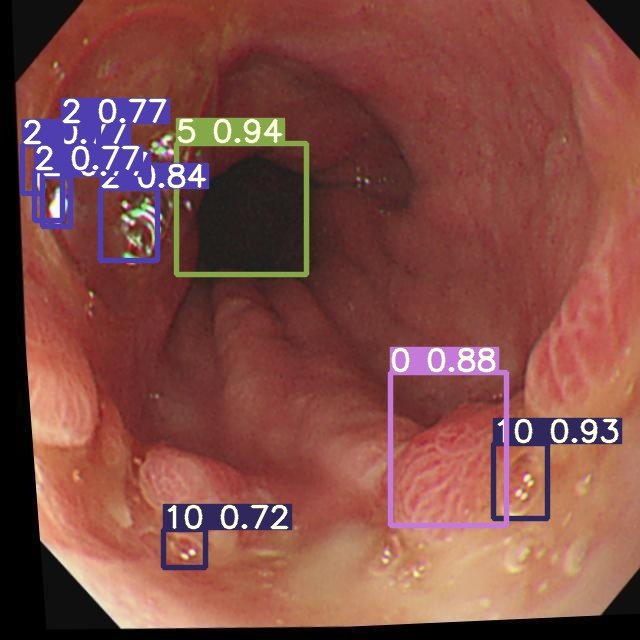

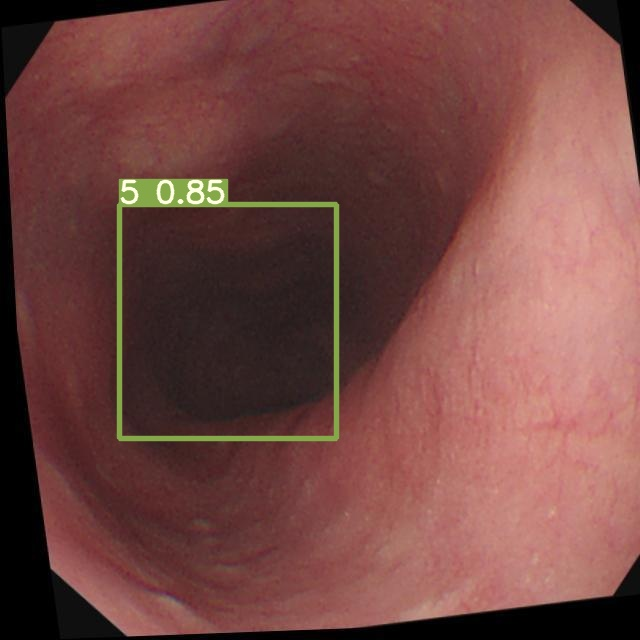

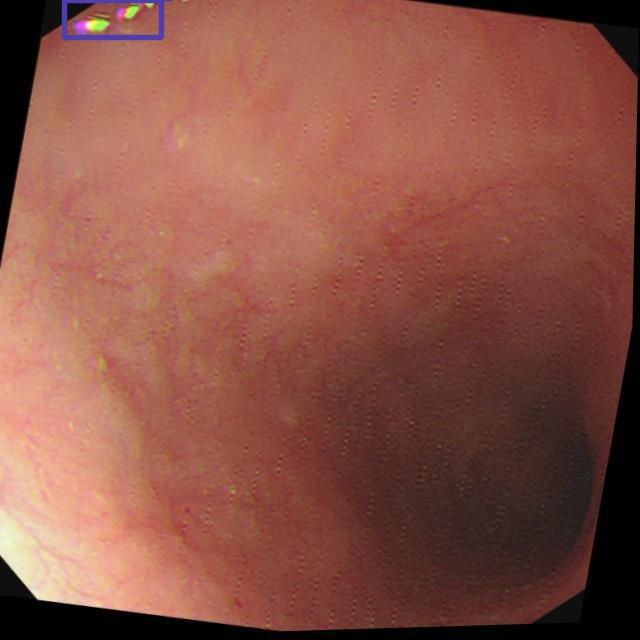

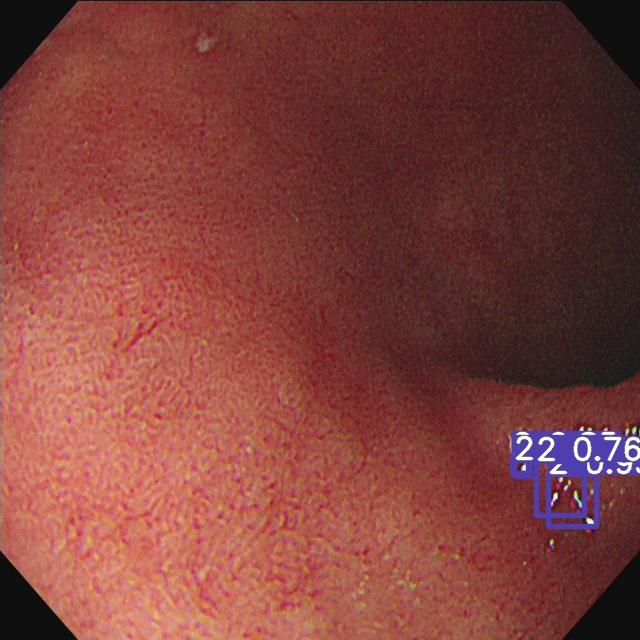

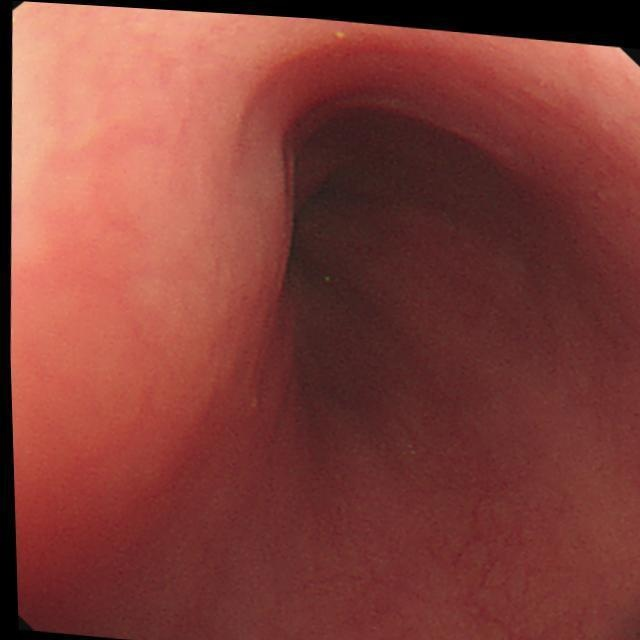

...

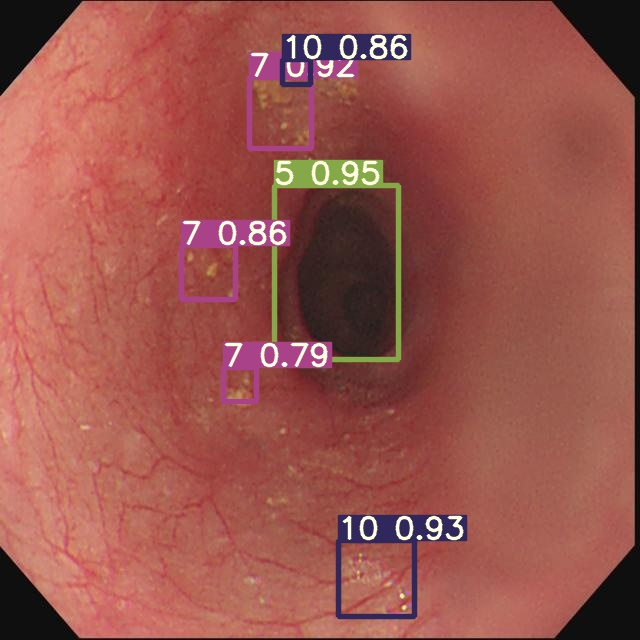

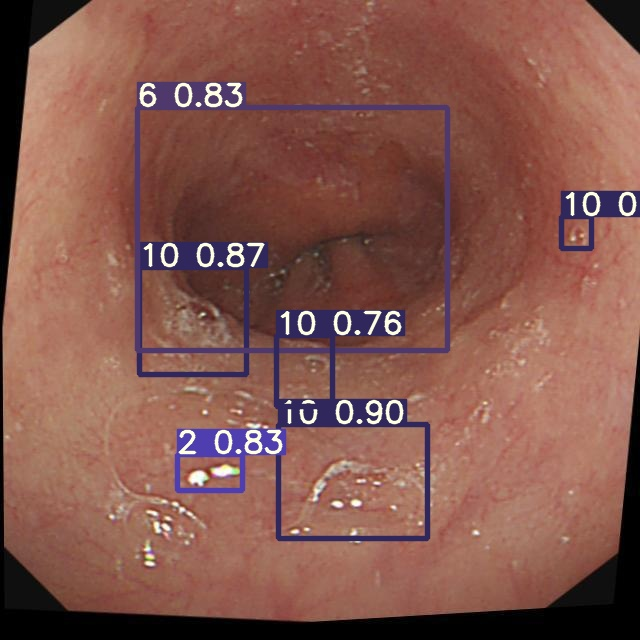

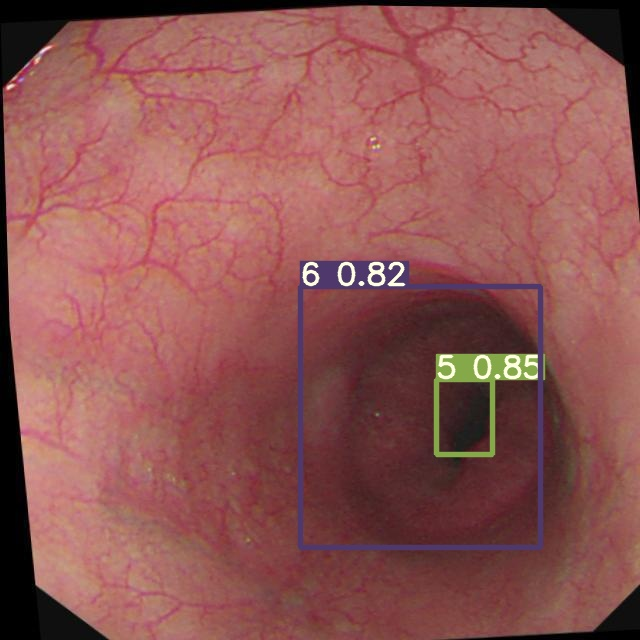

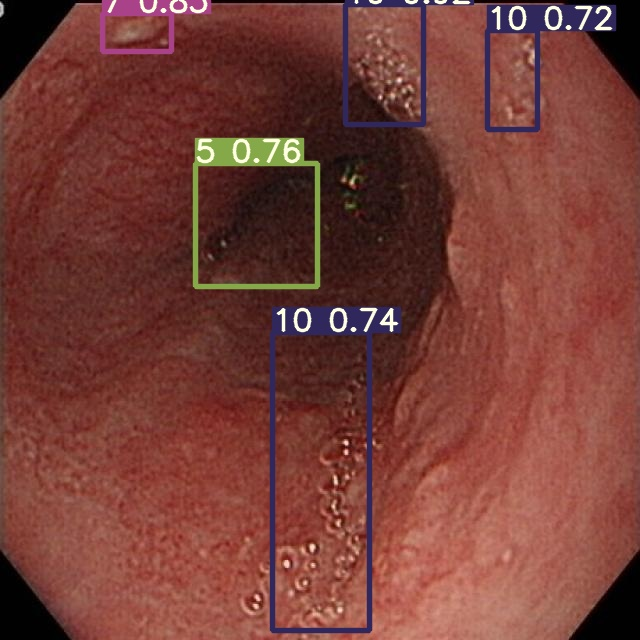

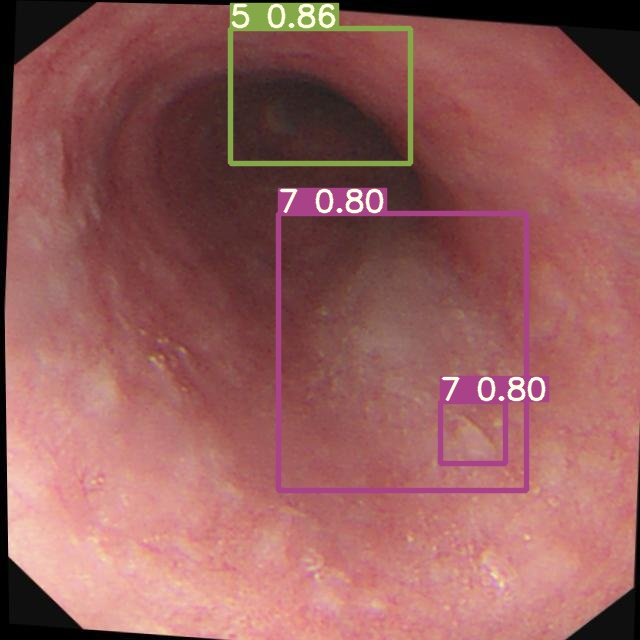

In [29]:
#display inference on ALL test images
#this looks much better with longer training above

import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/yolor/inference/output/*.jpg'): #assuming JPG
    display(Image(filename=imageName))
    print("\n")